# 매출 데이터 분석 실습

CE-WebSystem-L8-2의 순서에 따라 원본 점검 → 시각화 → 전처리 → 탐색적 데이터 분석을 수행합니다.
같은 폴더에 `sales_data.csv`를 두고 커널을 재시작한 뒤 모든 셀을 순서대로 실행합니다.

## 1. 데이터 읽기

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [2]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [3]:
df.iloc[0]

order_date         2023-01-01
shipping_date      2023-01-04
delivery_date      2023-01-03
region                     부산
category                 전자제품
product_id               2772
quantity                   61
unit_price           34977.69
customer_id               327
customer_age             67.0
customer_gender             M
satisfaction              1.0
status                    배송중
total_sales        2133639.09
Name: 0, dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [5]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


## 2. 데이터 점검

결측치·중복·총액 불일치·날짜 순서를 확인합니다. 이 단계에서는 데이터를 고치지 않습니다.

In [6]:
df.isna().sum()

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

In [7]:
(df.isnull().sum() / len(df) * 100).round(1)

order_date         0.0
shipping_date      0.0
delivery_date      0.5
region             0.0
category           0.0
product_id         0.0
quantity           0.0
unit_price         0.0
customer_id        0.0
customer_age       5.0
customer_gender    0.0
satisfaction       2.9
status             0.0
total_sales        0.0
dtype: float64

In [8]:
print(df.duplicated().sum())

26


In [9]:
df[df.duplicated(keep=False)].sort_values("order_date").head(4)

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
63,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1029,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1001,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34
128,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34


In [10]:
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print((diff > 1).sum())

22


In [11]:
cols = ["quantity", "unit_price", "total_sales"]
df.loc[diff > 1, cols].head(3)

,quantity,unit_price,total_sales
31,528,235225.85,22346455.75
188,943,303984.25,19151007.75
273,656,242263.07,18654256.39


In [12]:
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df[dates].agg(["min", "max"])

,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


In [13]:
today = pd.Timestamp.today()
late = df["shipping_date"] < df["order_date"]
rev = df["delivery_date"] < df["shipping_date"]
print("미래날짜 :", (df["order_date"] > today).sum())
print("배송일 < 주문일 :", late.sum())
print("도착일 < 배송일 :", rev.sum())

미래날짜 : 0
배송일 < 주문일 : 0
도착일 < 배송일 : 149


## 3. 시각화: 전처리 전에 분포 확인

수량 히스토그램과 박스플롯을 그린 뒤 IQR 상한을 계산합니다.
상한 밖이라는 사실만으로 오류를 확정하지 않고 다른 열의 값과 함께 판단합니다.

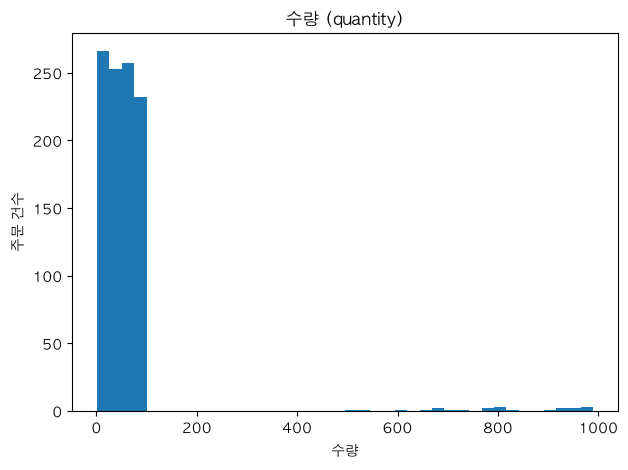

In [14]:
df["quantity"].plot.hist(bins=40, title="수량 (quantity)")
plt.xlabel("수량")
plt.ylabel("주문 건수")
plt.tight_layout()
plt.show()

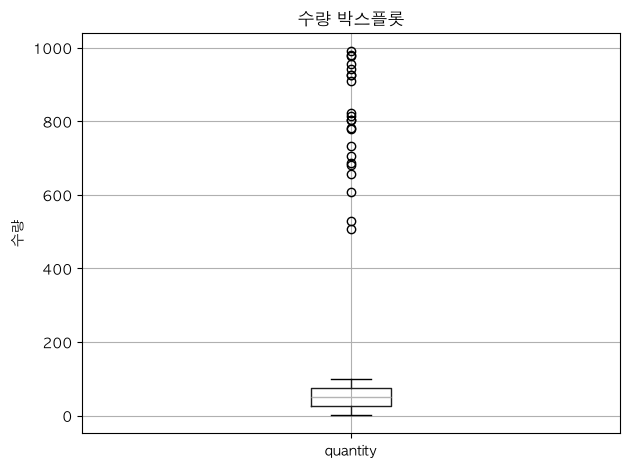

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0
상한 밖 수량 : 22


In [15]:
df.boxplot(column="quantity")
plt.title("수량 박스플롯")
plt.ylabel("수량")
plt.tight_layout()
plt.show()

Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)
print("상한 밖 수량 :", (df["quantity"] > Q3 + 1.5 * IQR).sum())

### [실습 3] 수량만 그런가?

수량·단가·총액·나이의 히스토그램을 나란히 그려 분포와 꼬리 모양을 비교합니다.

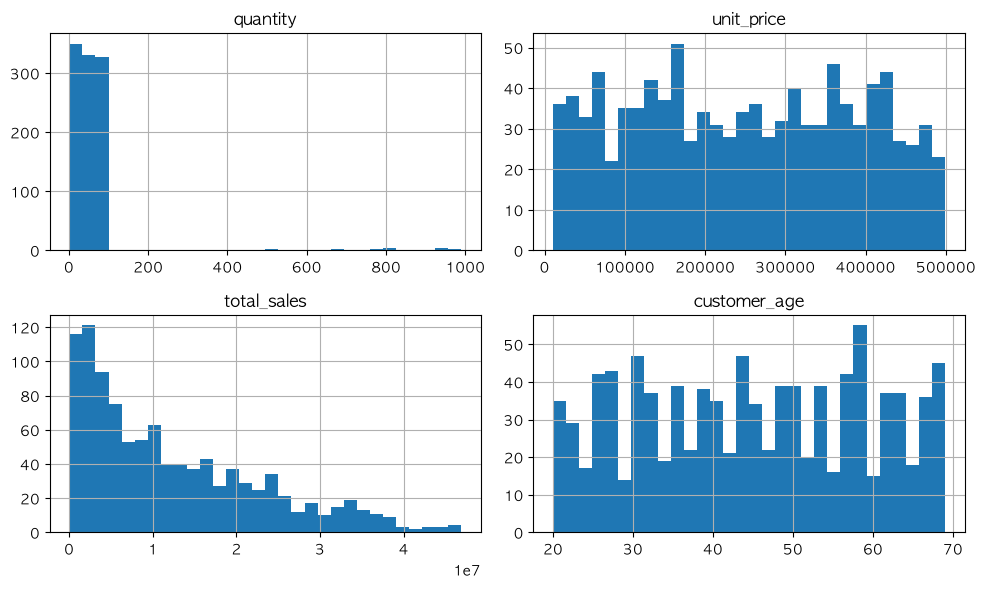

In [16]:
cols = ["quantity", "unit_price", "total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 4. 전처리: 유지·제거·복원·표시

### [실습 4] 평균으로 나이 결측치를 채워 보면

나이·만족도·도착일의 결측치는 유지합니다. 아래 `dropped`와 `age_mean`은 비교용이며 `df`에는 반영하지 않습니다.
평균으로 나이를 채우면 동일한 값 51개가 생겨 분포가 달라집니다.

1030 -> 979
평균 : 44.858
중앙값: 44.858
최빈값: 44.858


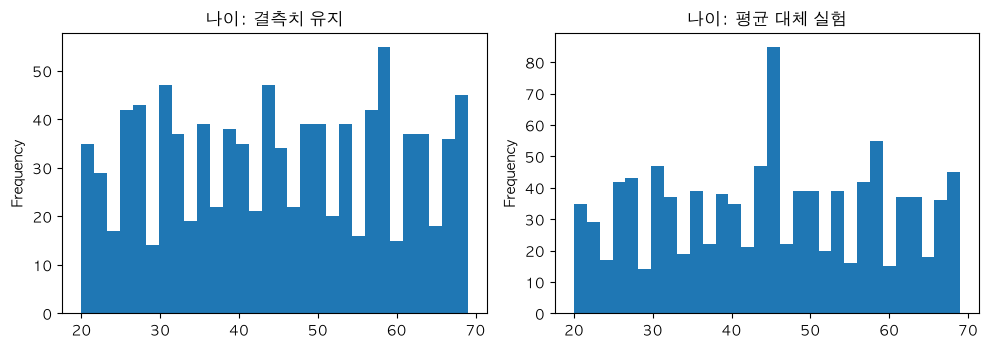

In [17]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

age_mean = df["customer_age"].fillna(df["customer_age"].mean())
print("평균 :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
df["customer_age"].plot.hist(bins=30, ax=ax[0], title="나이: 결측치 유지")
age_mean.plot.hist(bins=30, ax=ax[1], title="나이: 평균 대체 실험")
plt.tight_layout()
plt.show()

### 결측치는 유지하고 완전히 같은 중복 행만 제거

나이가 비어 있어도 다른 열은 분석에 사용할 수 있습니다. 결측 행을 통째로 버리지 않고 중복만 제거합니다.

In [18]:
print(df["customer_age"].count(), "/", len(df))
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

979 / 1030
1030 -> 1004


### 수량 오류의 근거 확인

IQR 상한은 150이며, 수량 100 초과라는 수업의 업무 규칙과 같은 22행을 가리킵니다.
해당 행의 총액을 단가로 나눈 값이 모두 정수이므로 총액이나 단가를 바꾸지 않고 수량을 복원합니다.

In [19]:
by_iqr = df["quantity"] > Q3 + 1.5 * IQR
by_rule = df["quantity"] > 100
print("IQR 규칙 :", by_iqr.sum(), " 업무 규칙 :", by_rule.sum(),
      " 둘이 같은 줄인가 :", (by_iqr == by_rule).all())

bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("이상 수량 중 금액이 안 맞는 줄 :", (diff[bad] > 1).sum())
ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)

IQR 규칙 : 22  업무 규칙 : 22  둘이 같은 줄인가 : True
이상 수량 중 금액이 안 맞는 줄 : 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

### [실습 5] 잘못 입력된 수량 22개 복원

업무 규칙과 총액 ÷ 단가의 값을 근거로 수량만 복원하고, 복원 건수·최대 수량·총액 불일치를 확인합니다.

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


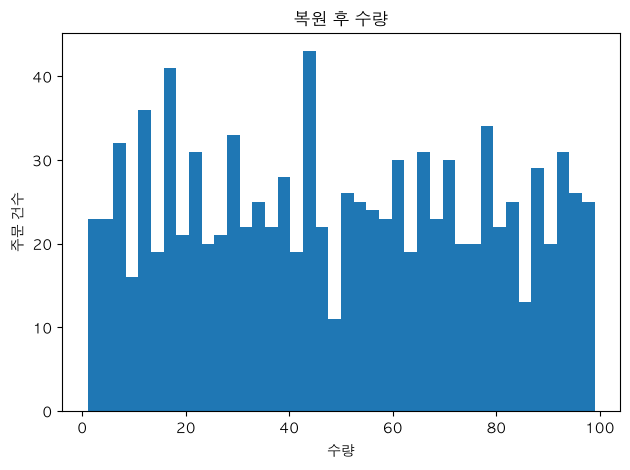

In [20]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(),
      " 총액 안 맞는 줄 :", (diff > 1).sum())

df["quantity"].plot.hist(bins=40, title="복원 후 수량")
plt.xlabel("수량")
plt.ylabel("주문 건수")
plt.tight_layout()
plt.show()

In [21]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].value_counts())
df.to_csv("sales_clean.csv", index=False)
df.shape

date_error
False    857
True     147
Name: count, dtype: int64


(1004, 15)

### 전처리 기록

| 점검 | 처리 | 전 | 후 | 근거 |
| --- | --- | --- | --- | --- |
| 나이·만족도·도착일 결측 | 유지 | 51·30·5건 | 51·30·5건 | 근거 없이 값을 만들지 않고 해당 계산에서만 제외 |
| 완전히 같은 행 | 뒤쪽 제거 | 1,030행, 중복 26행 | 1,004행, 중복 0행 | 같은 내용의 주문이 두 번 기록됨 |
| 수량·총액 불일치 | 수량을 총액 ÷ 단가로 복원 | 수량 최대 990, 불일치 22건 | 최대 99, 불일치 0건 | 100 초과 22행의 총액 ÷ 단가가 모두 정수 |
| 수량 IQR 상한 초과 | 위와 같은 수량 복원 | 22건 | 0건 | 업무 규칙과 같은 행을 가리킴 |
| 도착일 < 배송일 | `date_error` 표시 | 원본 149건 | 중복 제거 후 147건 표시 | 어느 날짜가 잘못됐는지 확정할 근거가 없음 |

`date_error`가 추가된 `sales_clean.csv`는 1,004행 × 15열입니다. 원본 CSV는 변경하지 않습니다.

## 5. 탐색적 데이터 분석

### Q1. 보통 주문은 어떤 것인가?

In [22]:
df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


수량 중앙값은 48개, 총액 중앙값은 9,425,457.90원입니다.
총액은 왜도 0.94로 오른쪽 꼬리가 있어 평균 12,413,727.16원보다 중앙값으로 보통 주문을 설명합니다.

### Q2. 어떤 값이 매출과 함께 움직이는가?

원본과 정리한 데이터의 상관계수를 비교하고 산점도·상관표·히트맵을 확인합니다.

수량-총액 상관계수 고치기 전 : 0.21  고친 뒤 : 0.67


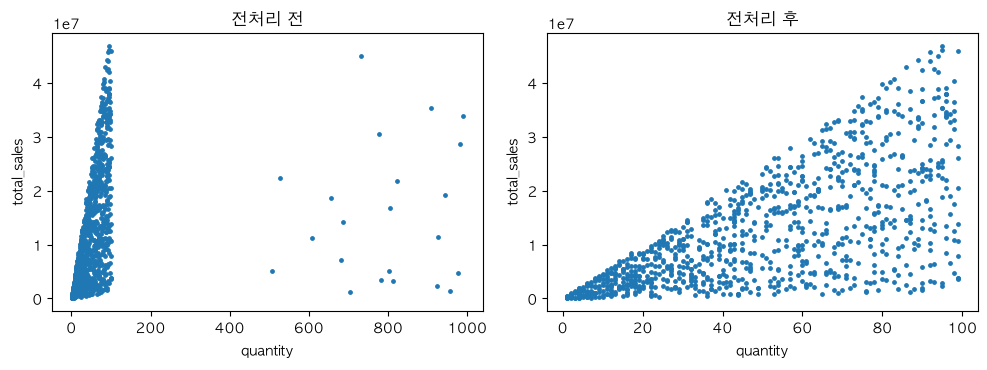

In [23]:
raw = pd.read_csv("sales_data.csv")
print("수량-총액 상관계수 고치기 전 :", round(raw["quantity"].corr(raw["total_sales"]), 2),
      " 고친 뒤 :", round(df["quantity"].corr(df["total_sales"]), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
raw.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[0], title="전처리 전")
df.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[1], title="전처리 후")
plt.tight_layout()
plt.show()

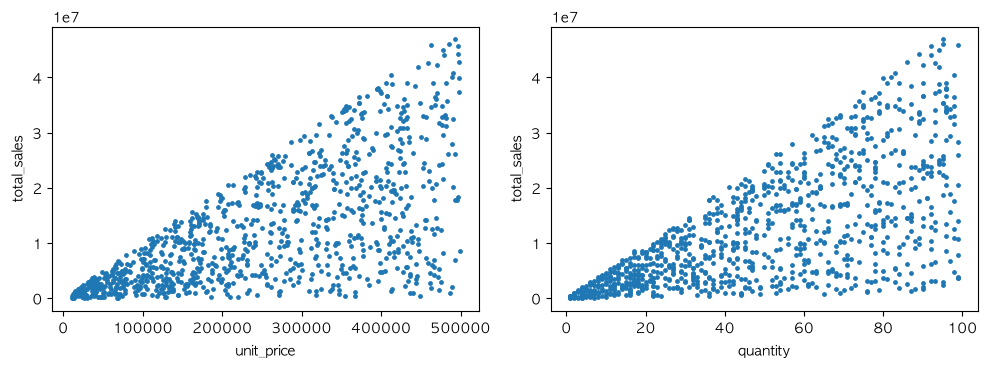

,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
df.plot.scatter(x="unit_price", y="total_sales", s=6, ax=ax[0])
df.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[1])
plt.tight_layout()
plt.show()

num = ["quantity", "unit_price", "total_sales", "customer_age", "satisfaction"]
df[num].corr().round(2)

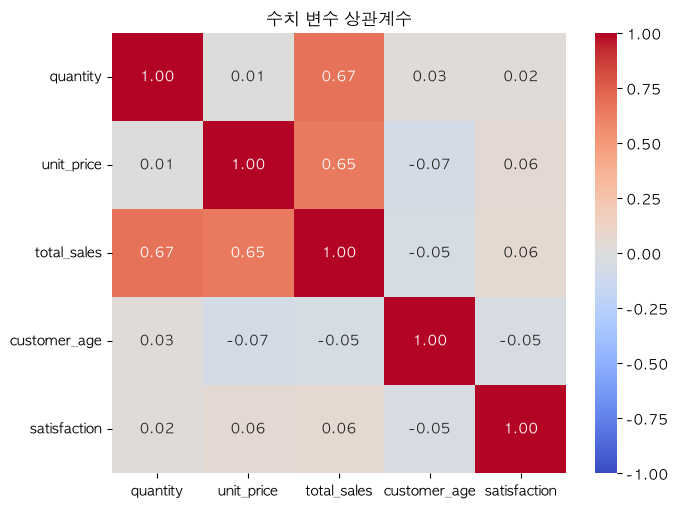

In [25]:
import seaborn as sns

plt.figure(figsize=(7, 5.2))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("수치 변수 상관계수")
plt.tight_layout()
plt.show()

수량과 총액의 상관계수는 전처리 전 0.21에서 전처리 후 0.67로 달라졌습니다.
총액과 단가의 상관계수는 0.65이며, 나이·만족도와 총액의 상관계수 절댓값은 0.1 미만입니다. 상관계수만으로 인과관계를 단정하지 않습니다.

### Q3. 카테고리·지역·달별 매출은 어떻게 다른가?

In [26]:
by_cat = df.groupby("category")["total_sales"].sum()
(by_cat / 1e8).round(1)

category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: total_sales, dtype: float64

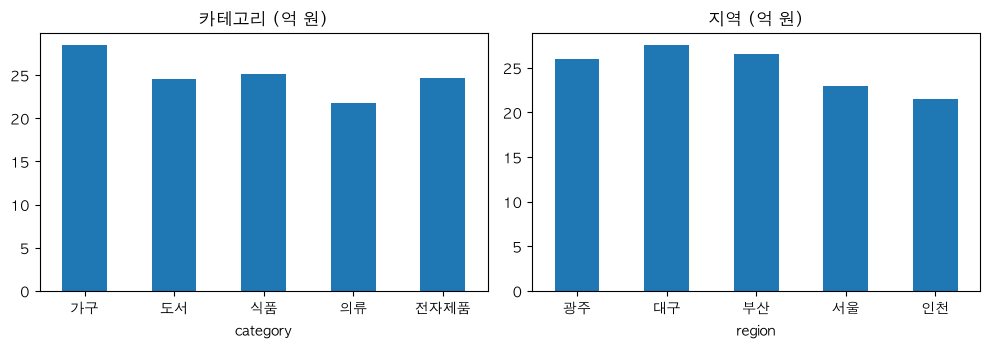

In [27]:
by_reg = df.groupby("region")["total_sales"].sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
(by_cat / 1e8).plot.bar(ax=ax[0], title="카테고리 (억 원)", rot=0)
(by_reg / 1e8).plot.bar(ax=ax[1], title="지역 (억 원)", rot=0)
plt.tight_layout()
plt.show()

### [실습 6] 지역 × 카테고리와 월별 매출

`pivot_table`로 두 범주를 함께 집계하고, 주문 날짜를 월 단위로 묶어 매출 변화를 확인합니다.

In [28]:
pv = df.pivot_table(index="region", columns="category",
                    values="total_sales", aggfunc="sum")
(pv / 1e8).round(1)

category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


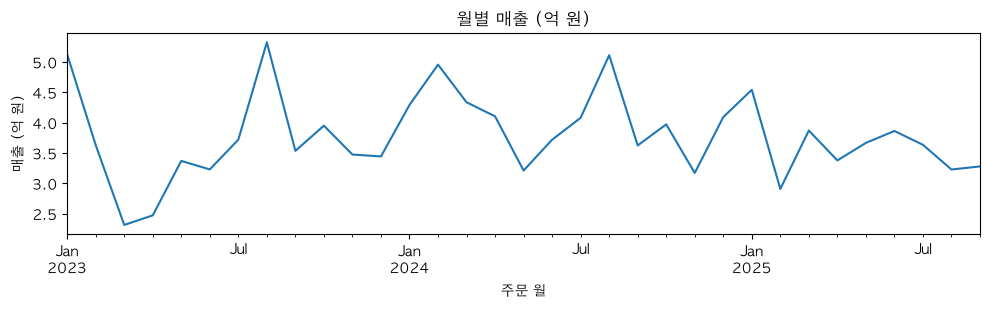

(Period('2023-08', 'M'), np.float64(5.3))

In [29]:
month = df["order_date"].dt.to_period("M")
monthly = df.groupby(month)["total_sales"].sum() / 1e8
monthly.plot(figsize=(10, 3.2), title="월별 매출 (억 원)")
plt.xlabel("주문 월")
plt.ylabel("매출 (억 원)")
plt.tight_layout()
plt.show()
monthly.idxmax(), round(monthly.max(), 1)

가구 매출이 28.4억 원으로 가장 많고 의류는 21.8억 원입니다. 가장 높은 월별 매출은 2023년 8월의 5.3억 원입니다.
이 자료로 광고 효과나 반품 원인, 다음 해 매출까지 설명하거나 예측하지 않습니다.